# Satelit — Deteksi Perubahan (dua citra beda waktu → "berubah / tidak" per piksel)
**Kapan dipakai:** ada citra daerah yang sama di dua waktu (sebelum/sesudah) dan diminta
menandai bagian yang berubah (bangunan baru, deforestasi, banjir, lahan terbuka).

**Idenya:** tiap piksel diberi feature: nilai band sebelum, sesudah, selisihnya, selisih
indeks NDVI/NDBI, dan besar selisih yang dihaluskan. RandomForest memilih "berubah / tidak"
per piksel. Ambang peluang dipilih di pasangan validasi (kelas sangat tidak seimbang).

**Langkah:**
1. Hitung feature per piksel, ambil sampel piksel dari pasangan latih.
2. Latih model, pilih ambang dengan F1 terbaik di pasangan validasi.
3. Buat peta perubahan untuk pasangan uji, simpan sebagai PNG.

**Data demo:** OSCD (Sentinel-2, 13 band, 10 m, perubahan perkotaan, lisensi non-komersial).
Latih 4 pasang, validasi 1, uji 2 (kota yang belum pernah dilihat).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from lightgbm import LGBMClassifier
from PIL import Image
from scipy.ndimage import uniform_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_recall_curve, precision_score, recall_score

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/oscd_sentinel2"   # GANTI saat lomba
BEFORE_NAME = "pasangan{}_sebelum.tif"     # {} diganti nomor pasangan
AFTER_NAME = "pasangan{}_sesudah.tif"
LABEL_NAME = "pasangan{}_label.tif"

TRAIN_PAIRS = ["00", "01", "03", "04"]
VALID_PAIRS = ["05"]          # dipakai memilih ambang peluang
TEST_PAIRS = ["07", "09"]
PIXELS_PER_PAIR = 40000       # sampel piksel latih per pasangan (citra utuh terlalu besar)
SMALL_WINDOW = 5              # jendela perataan selisih (piksel), meredam noise
LARGE_WINDOW = 15             # jendela lebih lebar, perubahan biasanya berupa bidang
SEED = 42
# Urutan 13 band Sentinel-2: B01 B02 B03 B04 B05 B06 B07 B08 B8A B09 B10 B11 B12
RED = 3                       # nomor band (mulai 0)
NIR = 7
SWIR = 11

## Langkah 1a — baca satu pasangan
Nilai band Sentinel-2 dibagi 10000 = pantulan 0–1.

In [3]:
def read_pair(number):
    before_file = rasterio.open(f"{DATA_FOLDER}/{BEFORE_NAME.format(number)}")
    after_file = rasterio.open(f"{DATA_FOLDER}/{AFTER_NAME.format(number)}")
    label_file = rasterio.open(f"{DATA_FOLDER}/{LABEL_NAME.format(number)}")
    before = before_file.read().astype("float32") / 10000
    after = after_file.read().astype("float32") / 10000
    label = label_file.read(1)
    return before, after, label


# coba pada pasangan latih pertama
before, after, label = read_pair(TRAIN_PAIRS[0])
print("band x tinggi x lebar:", before.shape, "| porsi piksel berubah:", label.mean().round(3))

band x tinggi x lebar: (13, 353, 426) | porsi piksel berubah: 0.057


## Langkah 1b — feature per piksel
Indeks dihitung dari nilai asli. Lalu tiap band disamakan skalanya (rata-rata 0, simpangan 1)
per citra, supaya beda cuaca/musim antar tanggal teredam.
Hasil: (tinggi, lebar, jumlah feature).

In [4]:
def pixel_features(before, after):
    ndvi_before = (before[NIR] - before[RED]) / (before[NIR] + before[RED] + 1e-6)
    ndvi_after = (after[NIR] - after[RED]) / (after[NIR] + after[RED] + 1e-6)
    ndbi_before = (before[SWIR] - before[NIR]) / (before[SWIR] + before[NIR] + 1e-6)
    ndbi_after = (after[SWIR] - after[NIR]) / (after[SWIR] + after[NIR] + 1e-6)
    before = before - before.mean(axis=(1, 2), keepdims=True)
    before = before / before.std(axis=(1, 2), keepdims=True)
    after = after - after.mean(axis=(1, 2), keepdims=True)
    after = after / after.std(axis=(1, 2), keepdims=True)
    difference = after - before
    size = np.sqrt((difference ** 2).sum(axis=0))
    extra = np.stack([ndvi_after - ndvi_before, ndbi_after - ndbi_before, size,
                      uniform_filter(size, SMALL_WINDOW), uniform_filter(size, LARGE_WINDOW)])
    features = np.concatenate([before, after, difference, extra])
    return features.transpose(1, 2, 0)


# coba pada pasangan tadi
features = pixel_features(before, after)
print(features.shape)

(353, 426, 44)


## Langkah 1c — sampel piksel dari pasangan latih

In [5]:
rng = np.random.default_rng(SEED)
feature_parts = []
label_parts = []
for number in TRAIN_PAIRS:
    before, after, label = read_pair(number)
    features = pixel_features(before, after)
    rows = rng.choice(label.size, PIXELS_PER_PAIR, replace=False)
    feature_parts.append(features.reshape(-1, features.shape[2])[rows])
    label_parts.append(label.reshape(-1)[rows])
X_train = np.concatenate(feature_parts)
y_train = np.concatenate(label_parts)
print(X_train.shape, "| porsi piksel berubah:", y_train.mean().round(3))

(160000, 44) | porsi piksel berubah: 0.052


## Langkah 2a — model
Piksel berubah hanya sekitar 5%, jadi kelas itu diberi bobot lebih (`class_weight`).
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                               class_weight="balanced_subsample", n_jobs=4, random_state=SEED)
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced",
#                        n_jobs=4, verbose=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then conside

## Langkah 2b — pilih ambang peluang di pasangan validasi
Dengan kelas tidak seimbang, ambang 0.5 jarang terbaik. Dicari ambang dengan F1 tertinggi.

In [7]:
before, after, label = read_pair(VALID_PAIRS[0])
features = pixel_features(before, after)
probabilities = model.predict_proba(features.reshape(-1, features.shape[2]))[:, 1]
precision, recall, candidates = precision_recall_curve(label.reshape(-1), probabilities)
candidate_f1 = 2 * precision * recall / (precision + recall + 1e-9)
THRESHOLD = candidates[candidate_f1[:-1].argmax()]
print("ambang terpilih:", THRESHOLD.round(3), "| F1 validasi:", candidate_f1.max().round(3))

ambang terpilih: 0.153 | F1 validasi: 0.353


## Langkah 3 — peta perubahan pasangan uji
Tiap peta disimpan sebagai `mask_<nomor>.png` (putih = berubah) di folder notebook.

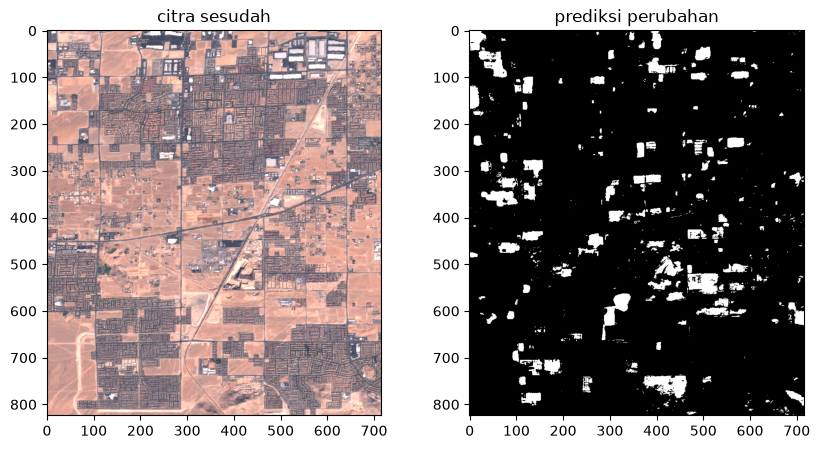

In [8]:
change_maps = {}
for number in TEST_PAIRS:
    before, after, label = read_pair(number)
    features = pixel_features(before, after)
    probabilities = model.predict_proba(features.reshape(-1, features.shape[2]))[:, 1]
    change_map = (probabilities > THRESHOLD).reshape(label.shape)
    change_maps[number] = change_map
    Image.fromarray(change_map.astype("uint8") * 255).save(f"mask_{number}.png")

after_file = rasterio.open(f"{DATA_FOLDER}/{AFTER_NAME.format(TEST_PAIRS[-1])}")
rgb = after_file.read([4, 3, 2]).transpose(1, 2, 0)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(np.clip(rgb / 3000, 0, 1))
axes[0].set_title("citra sesudah")
axes[1].imshow(change_maps[TEST_PAIRS[-1]], cmap="gray")
axes[1].set_title("prediksi perubahan")
fig.savefig("perubahan.png", dpi=100, bbox_inches="tight")
plt.show()

## Simpan ringkasan
Keluaran utama = file `mask_*.png`. CSV ini hanya ringkasan per pasangan (ganti sesuai format
soal, misalnya satu baris per piksel atau per patch).

In [9]:
changed_percent = []
for number in TEST_PAIRS:
    changed_percent.append(change_maps[number].mean() * 100)

submission = pd.DataFrame()
submission["pair"] = TEST_PAIRS
submission["changed_percent"] = changed_percent
submission.to_csv("submission.csv", index=False)
submission

,pair,changed_percent
0,07,7.992811
1,09,8.426161


## Cek dengan kunci jawaban (HAPUS saat lomba)

In [10]:
for number in TEST_PAIRS:
    before, after, label = read_pair(number)
    truth = label.reshape(-1)
    predicted = change_maps[number].reshape(-1)
    print(number, "| F1:", round(f1_score(truth, predicted), 3),
          "| precision:", round(precision_score(truth, predicted), 3),
          "| recall:", round(recall_score(truth, predicted), 3))

07 | F1: 0.451 | precision: 0.506 | recall: 0.407


09 | F1: 0.694 | precision: 0.663 | recall: 0.728
